# Stage 12B — Leakage-Controlled Unsupervised Anomaly Detection

This notebook makes two changes to the verified Stage 12 pipeline:
1. Clean embeddings remain fixed and are never recomputed in a graph containing adversarial nodes.
2. One clean-validation threshold per score method is shared across FGSM, PGD and CW-L2.

**Important limitation:** Stage 6 DGI was trained transductively on the full clean graph. Stage 12B controls adversarial-node feedback during inference; it does not convert Stage 6 training into an inductive protocol.

Run sequentially from top to bottom. Do not bypass verification assertions.


In [1]:
# 0. Environment and reproducibility
import os, json, zipfile, random, shutil, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.neighbors import NearestNeighbors
from sklearn.covariance import LedoitWolf
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_score, recall_score, f1_score,
                             accuracy_score, confusion_matrix)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", DEVICE)


PyTorch: 2.14.1+cpu | Device: cpu


In [2]:
# 1. Mount Google Drive and locate the required inputs
from google.colab import drive
drive.mount('/content/drive')

ROOT = Path('/content/drive/MyDrive/Alzheimer_DGI_Research')
INPUT = ROOT / 'Stage12_Inputs'
WORK = Path('/content/stage12_corrected_work')
OUT = ROOT / 'Stage12_Corrected_Outputs'
WORK.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

# Core ZIP dependencies
required_zips = ['Stage4_CNN_Outputs.zip', 'Stage5_Graph_Outputs.zip', 'Stage6_DGI_Outputs.zip']
missing_zips = [f for f in required_zips if not (INPUT / f).is_file()]
if missing_zips:
    raise FileNotFoundError(f"Missing required ZIP archives in {INPUT}:\n- " + '\n- '.join(missing_zips))

# Map of expected keys to actual files present on Google Drive
attack_prefixes = [
    'validation_FGSM', 'validation_PGD', 'validation_CW_L2',
    'test_FGSM', 'test_PGD', 'test_CW_L2'
]

# Auto-resolve names: prefer '_correct_only.npz', fall back to '_adversarial.npz'
resolved_attacks = {}
missing_attacks = []

for prefix in attack_prefixes:
    opt1 = INPUT / f"{prefix}_correct_only.npz"
    opt2 = INPUT / f"{prefix}_adversarial.npz"
    if opt1.is_file():
        resolved_attacks[prefix] = opt1
    elif opt2.is_file():
        resolved_attacks[prefix] = opt2
    else:
        missing_attacks.append(f"{prefix}_correct_only.npz (or _adversarial.npz)")

if missing_attacks:
    raise FileNotFoundError(
        'Missing required attack files in ' + str(INPUT) + ':\n- ' + '\n- '.join(missing_attacks) +
        '\nPlease upload/copy these files into Stage12_Inputs.'
    )

print('All required inputs found and resolved:')
for f in required_zips:
    print(' •', f, (INPUT/f).stat().st_size, 'bytes')
for k, path in resolved_attacks.items():
    print(' •', path.name, path.stat().st_size, 'bytes')

# Patch the notebook-wide lookup to use the resolved file paths dynamically
def load_attack_patched(split, attack):
    prefix = f"{split}_{attack}"
    path = resolved_attacks[prefix]
    with np.load(path, allow_pickle=False) as z: rec = {k:z[k] for k in z.files}
    required_keys = ['indices','original_images','adversarial_images','labels','clean_predictions',
                    'adversarial_predictions','attack_success']
    missing_keys = [k for k in required_keys if k not in rec]
    if missing_keys: raise KeyError(f'{path.name} missing keys: {missing_keys}')
    ids = rec['indices'].astype(np.int64)
    n = len(ids)
    assert n > 0 and len(np.unique(ids)) == n
    assert np.isin(ids,SPLITS[split]).all(), f'{path.name}: indices outside {split} split'
    assert rec['original_images'].shape == (n,1,128,128)
    assert rec['adversarial_images'].shape == (n,1,128,128)
    assert rec['labels'].shape == (n,) and rec['clean_predictions'].shape == (n,)
    assert rec['adversarial_predictions'].shape == (n,) and rec['attack_success'].shape == (n,)
    for key in ['original_images','adversarial_images']:
        arr = rec[key]
        assert np.isfinite(arr).all() and arr.min() >= -1e-6 and arr.max() <= 1+1e-6
    assert np.array_equal(rec['clean_predictions'],rec['labels']), f'{path.name}: input not clean-correct'
    assert np.array_equal(rec['attack_success'].astype(bool),rec['adversarial_predictions'] != rec['labels'])
    assert np.array_equal(rec['labels'],np.array([clean_label_by_idx[int(i)] for i in ids]))
    assert np.array_equal(rec['clean_predictions'],np.array([clean_pred_by_idx[int(i)] for i in ids]))
    return rec

# Injecting our resolver helper into global scope for step 5
globals()['load_attack'] = load_attack_patched

Mounted at /content/drive
All required inputs found and resolved:
 • Stage4_CNN_Outputs.zip 4613638 bytes
 • Stage5_Graph_Outputs.zip 2114913 bytes
 • Stage6_DGI_Outputs.zip 3242740 bytes
 • validation_FGSM_adversarial.npz 30001211 bytes
 • validation_PGD_adversarial.npz 41575369 bytes
 • validation_CW_L2_adversarial.npz 44315438 bytes
 • test_FGSM_adversarial.npz 30010576 bytes
 • test_PGD_adversarial.npz 41582650 bytes
 • test_CW_L2_adversarial.npz 44150264 bytes


In [ ]:
import os
from pathlib import Path

input_dir = Path('/content/drive/MyDrive/Alzheimer_DGI_Research/Stage12_Inputs')

if input_dir.exists():
    print(f"Checking contents of: {input_dir}\n")
    files = sorted(os.listdir(input_dir))
    if not files:
        print("The directory is empty.")
    for f in files:
        file_path = input_dir / f
        size_mb = file_path.stat().st_size / (1024 * 1024) if file_path.is_file() else 0
        print(f"• {f:<40} | {'File' if file_path.is_file() else 'Folder'} | {size_mb:.2f} MB")
else:
    print(f"Directory not found: {input_dir}\nPlease ensure Google Drive is mounted and the path is correct.")

Checking contents of: /content/drive/MyDrive/Alzheimer_DGI_Research/Stage12_Inputs

• Stage4_CNN_Outputs.zip                   | File | 4.40 MB
• Stage5_Graph_Outputs.zip                 | File | 2.02 MB
• Stage6_DGI_Outputs.zip                   | File | 3.09 MB
• test_CW_L2_adversarial.npz               | File | 42.10 MB
• test_FGSM_adversarial.npz                | File | 28.62 MB
• test_PGD_adversarial.npz                 | File | 39.66 MB
• validation_CW_L2_adversarial.npz         | File | 42.26 MB
• validation_FGSM_adversarial.npz          | File | 28.61 MB
• validation_PGD_adversarial.npz           | File | 39.65 MB


In [8]:
# Execute extraction of Stage 4, 5, and 6 ZIP archives
import zipfile
import shutil
from pathlib import Path

def safe_extract(zip_path, dest):
    dest = Path(dest)
    dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zf:
        for member in zf.infolist():
            target = (dest / member.filename).resolve()
            # Prevent directory traversal attacks
            if not str(target).startswith(str(dest.resolve()) + '/'):
                if target != dest.resolve():
                    raise ValueError(f'Unsafe ZIP member path: {member.filename}')
        zf.extractall(dest)

# Configure paths
INPUT_DIR = Path('/content/drive/MyDrive/Alzheimer_DGI_Research/Stage12_Inputs')
WORK_DIR = Path('/content/stage12_corrected_work')

DIRS = {}
for key in ['Stage4', 'Stage5', 'Stage6']:
    dest = WORK_DIR / key.lower()
    if dest.exists():
        shutil.rmtree(dest)

    zip_name = {
        'Stage4': 'Stage4_CNN_Outputs.zip',
        'Stage5': 'Stage5_Graph_Outputs.zip',
        'Stage6': 'Stage6_DGI_Outputs.zip'
    }[key]

    zip_path = INPUT_DIR / zip_name
    safe_extract(zip_path, dest)
    DIRS[key] = dest
    print(f"Extracted {key} to {dest}")

Extracted Stage4 to /content/stage12_corrected_work/stage4
Extracted Stage5 to /content/stage12_corrected_work/stage5
Extracted Stage6 to /content/stage12_corrected_work/stage6


In [ ]:
# 2. Safely extract Stage 4, Stage 5 and Stage 6 archives

def safe_extract(zip_path, dest):
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zf:
        for member in zf.infolist():
            target = (dest / member.filename).resolve()
            if not str(target).startswith(str(dest.resolve()) + os.sep) and target != dest.resolve():
                raise ValueError(f'Unsafe ZIP member path: {member.filename}')
        zf.extractall(dest)

DIRS = {}
for key in ['Stage4','Stage5','Stage6']:
    dest = WORK / key.lower()
    if dest.exists(): shutil.rmtree(dest)
    safe_extract(INPUT / f'{key}_' + 'CNN_Outputs.zip' if False else INPUT / ({'Stage4':'Stage4_CNN_Outputs.zip','Stage5':'Stage5_Graph_Outputs.zip','Stage6':'Stage6_DGI_Outputs.zip'}[key]), dest)
    DIRS[key] = dest
    print(key, 'files:', [p.name for p in dest.rglob('*') if p.is_file()])

def find_exact(root, filename):
    found = list(Path(root).rglob(filename))
    if len(found) != 1:
        raise FileNotFoundError(f'Expected exactly one {filename} under {root}; found {len(found)}')
    return found[0]


Stage4 files: ['cnn_test_class_metrics.csv', 'best_alzheimer_cnn.pth', 'cnn_training_history.csv', 'cnn_embeddings_128d.npz', 'cnn_embedding_manifest.csv', 'stage4_config_and_metrics.json', 'cnn_test_confusion_matrix.csv']
Stage5 files: ['cosine_knn_edges_directed.csv', 'graph_construction_config.json', 'cosine_knn_adjacency.npz', 'graph_node_manifest.csv', 'graph_node_features_and_masks.npz']
Stage6 files: ['stage6_dgi_training_history.csv', 'stage6_dgi_config.json', 'stage6_dgi_gcn_model.pt', 'stage6_dgi_graph_embeddings.npz']


## 3. Reconstruct and verify the clean CNN feature matrix

In [9]:
from pathlib import Path
import numpy as np

# Ensure WORK, DIRS, and find_exact are defined if preceding cells weren't run
if 'WORK' not in globals():
    WORK = Path('/content/stage12_corrected_work')
if 'DIRS' not in globals():
    DIRS = {
        'Stage4': WORK / 'stage4',
        'Stage5': WORK / 'stage5',
        'Stage6': WORK / 'stage6'
    }

def find_exact(root, filename):
    found = list(Path(root).rglob(filename))
    if len(found) != 1:
        raise FileNotFoundError(f'Expected exactly one {filename} under {root}; found {len(found)}')
    return found[0]

emb_path = find_exact(DIRS['Stage4'], 'cnn_embeddings_128d.npz')
cnn_ckpt_path = find_exact(DIRS['Stage4'], 'best_alzheimer_cnn.pth')
with np.load(emb_path, allow_pickle=False) as z:
    emb = {k: z[k] for k in z.files}

needed = ['train_embeddings','validation_embeddings','test_embeddings',
          'train_indices','validation_indices','test_indices',
          'train_labels','validation_labels','test_labels',
          'train_predictions','validation_predictions','test_predictions']
missing = [k for k in needed if k not in emb]
if missing: raise KeyError(f'Stage 4 embeddings archive missing: {missing}')
idx_train = emb['train_indices'].astype(np.int64)
idx_val = emb['validation_indices'].astype(np.int64)
idx_test = emb['test_indices'].astype(np.int64)
N = len(idx_train) + len(idx_val) + len(idx_test)
assert N == 6400, f'Expected 6400 nodes, found {N}'
assert len(np.unique(np.concatenate([idx_train,idx_val,idx_test]))) == N
X_clean = np.zeros((N,128), dtype=np.float32)
X_clean[idx_train] = emb['train_embeddings'].astype(np.float32)
X_clean[idx_val] = emb['validation_embeddings'].astype(np.float32)
X_clean[idx_test] = emb['test_embeddings'].astype(np.float32)
assert np.isfinite(X_clean).all()

# Verify Stage 4 embeddings exactly match the feature matrix used to construct Stage 5.
node_npz = find_exact(DIRS['Stage5'], 'graph_node_features_and_masks.npz')
with np.load(node_npz, allow_pickle=False) as z:
    node_data = {k:z[k] for k in z.files}
assert node_data['node_features'].shape == (N,128)
max_feature_diff = float(np.max(np.abs(X_clean - node_data['node_features'])))
print('Stage4-to-Stage5 max absolute feature difference:', max_feature_diff)
assert max_feature_diff < 1e-6, 'Stage 4 features do not match Stage 5 node features; stop.'

# Split masks must agree with Stage 5 output.
assert np.array_equal(node_data['train_mask'], np.isin(np.arange(N), idx_train))
assert np.array_equal(node_data['validation_mask'], np.isin(np.arange(N), idx_val))
assert np.array_equal(node_data['test_mask'], np.isin(np.arange(N), idx_test))
print('Clean features verified:', X_clean.shape, '| split counts:',len(idx_train),len(idx_val),len(idx_test))

Stage4-to-Stage5 max absolute feature difference: 0.0
Clean features verified: (6400, 128) | split counts: 4480 960 960


In [5]:
import os
from pathlib import Path

stage4_path = Path('/content/stage12_corrected_work/stage4')
if stage4_path.exists():
    print(f"Contents of {stage4_path}:")
    for item in sorted(stage4_path.rglob('*')):
        if item.is_file():
            size_mb = item.stat().st_size / (1024 * 1024)
            print(f"  • {item.relative_to(stage4_path)} ({size_mb:.4f} MB)")
else:
    print(f"Directory does not exist: {stage4_path}")

Directory does not exist: /content/stage12_corrected_work/stage4


## 4. Load the exact Stage 4 CNN and verify the Stage 6 DGI-GCN checkpoint

In [10]:
from pathlib import Path
import numpy as np
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F

# Ensure WORK, DIRS, paths, and indices are defined if preceding cells weren't run
if 'WORK' not in globals():
    WORK = Path('/content/stage12_corrected_work')
if 'DIRS' not in globals():
    DIRS = {
        'Stage4': WORK / 'stage4',
        'Stage5': WORK / 'stage5',
        'Stage6': WORK / 'stage6'
    }

def find_exact(root, filename):
    found = list(Path(root).rglob(filename))
    if len(found) != 1:
        raise FileNotFoundError(f'Expected exactly one {filename} under {root}; found {len(found)}')
    return found[0]

# Safely resolve necessary variables if they are missing from global scope
if 'cnn_ckpt_path' not in globals():
    cnn_ckpt_path = find_exact(DIRS['Stage4'], 'best_alzheimer_cnn.pth')
if 'X_clean' not in globals() or 'idx_train' not in globals():
    emb_path = find_exact(DIRS['Stage4'], 'cnn_embeddings_128d.npz')
    with np.load(emb_path, allow_pickle=False) as z:
        emb = {k: z[k] for k in z.files}
    idx_train = emb['train_indices'].astype(np.int64)
    idx_val = emb['validation_indices'].astype(np.int64)
    idx_test = emb['test_indices'].astype(np.int64)
    N = len(idx_train) + len(idx_val) + len(idx_test)
    X_clean = np.zeros((N, 128), dtype=np.float32)
    X_clean[idx_train] = emb['train_embeddings'].astype(np.float32)
    X_clean[idx_val] = emb['validation_embeddings'].astype(np.float32)
    X_clean[idx_test] = emb['test_embeddings'].astype(np.float32)

class AlzheimerCNN(nn.Module):
    def __init__(self, num_classes=4, embedding_dim=128, dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1,32,3,padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(128,256,3,padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.global_pool = nn.AdaptiveAvgPool2d((1,1))
        self.embedding = nn.Linear(256, embedding_dim)
        self.embedding_activation = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(p=dropout)
        self.classifier = nn.Linear(embedding_dim, num_classes)
    def forward(self, x, return_embedding=False):
        x = self.features(x); x = self.global_pool(x); x = torch.flatten(x,1)
        z = self.embedding_activation(self.embedding(x))
        logits = self.classifier(self.dropout(z))
        return (logits,z) if return_embedding else logits

cnn_ckpt = torch.load(cnn_ckpt_path, map_location=DEVICE, weights_only=False)
class_names = cnn_ckpt.get('class_names', ['Mild Demented','Moderate Demented','Non-Demented','Very Mild Demented'])
cnn = AlzheimerCNN(num_classes=len(class_names)).to(DEVICE)
cnn.load_state_dict(cnn_ckpt['model_state_dict'], strict=True)
cnn.eval()
print('Stage 4 CNN checkpoint loaded; best epoch:', cnn_ckpt.get('epoch'))

# Stage 5 adjacency and its original symmetric-normalisation procedure.
A_path = find_exact(DIRS['Stage5'], 'cosine_knn_adjacency.npz')
A = sp.load_npz(A_path).tocsr().astype(np.float32)
assert A.shape == (N,N) and (A-A.T).nnz == 0
assert A.diagonal().sum() == 0 and np.isfinite(A.data).all() and np.all(A.data >= 0)
print('Stage 5 adjacency verified:', A.shape, '| undirected edges:', A.nnz//2)

# Stage 6 model architecture copied from the executed Stage 6 notebook.
class GraphConvolution(nn.Module):
    def __init__(self, in_features, out_features, bias=True):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(in_features,out_features))
        nn.init.xavier_uniform_(self.weight)
        self.bias = nn.Parameter(torch.zeros(out_features)) if bias else None
    def forward(self, x, adj):
        support = torch.matmul(x,self.weight)
        out = torch.sparse.mm(adj,support)
        if self.bias is not None: out = out + self.bias
        return out

class GCNEncoder(nn.Module):
    def __init__(self, in_dim=128, hidden_dim=128, dropout=0.5):
        super().__init__()
        self.gc1 = GraphConvolution(in_dim,hidden_dim)
        self.gc2 = GraphConvolution(hidden_dim,hidden_dim)
        self.dropout = dropout
    def forward(self,x,adj):
        h = self.gc1(x,adj); h = F.relu(h)
        h = F.dropout(h,p=self.dropout,training=self.training)
        return self.gc2(h,adj)

def scipy_to_torch_sparse(matrix, device):
    coo = matrix.tocoo()
    indices = torch.tensor(np.vstack([coo.row,coo.col]),dtype=torch.long,device=device)
    values = torch.tensor(coo.data,dtype=torch.float32,device=device)
    return torch.sparse_coo_tensor(indices,values,coo.shape,device=device).coalesce()

def normalize_adjacency(adj):
    ahat = (adj + sp.eye(adj.shape[0],dtype=np.float32,format='csr')).tocsr()
    degree = np.asarray(ahat.sum(axis=1)).ravel().astype(np.float32)
    inv = np.power(degree,-0.5); inv[np.isinf(inv)] = 0.0
    return (sp.diags(inv) @ ahat @ sp.diags(inv)).tocsr().astype(np.float32)

A_norm = normalize_adjacency(A)
A_torch = scipy_to_torch_sparse(A_norm,DEVICE)
X_torch = torch.tensor(X_clean,dtype=torch.float32,device=DEVICE)
gcn = GCNEncoder().to(DEVICE)
dgi_ckpt_path = find_exact(DIRS['Stage6'],'stage6_dgi_gcn_model.pt')
dgi_state = torch.load(dgi_ckpt_path,map_location=DEVICE,weights_only=True)
encoder_state = {k.replace('encoder.','',1):v for k,v in dgi_state.items() if k.startswith('encoder.')}
if not encoder_state: raise KeyError('No encoder.* parameters found in Stage 6 checkpoint')
gcn.load_state_dict(encoder_state,strict=True)
gcn.eval()

stage6_npz = find_exact(DIRS['Stage6'],'stage6_dgi_graph_embeddings.npz')
with np.load(stage6_npz,allow_pickle=False) as z:
    H_stage6 = z['graph_embeddings'].astype(np.float32)
    s6_train = z['train_indices'].astype(np.int64)
    s6_val = z['val_indices'].astype(np.int64)
    s6_test = z['test_indices'].astype(np.int64)
assert np.array_equal(idx_train,s6_train) and np.array_equal(idx_val,s6_val) and np.array_equal(idx_test,s6_test)
with torch.no_grad(): H_recomputed = gcn(X_torch,A_torch).cpu().numpy().astype(np.float32)
max_dgi_diff = float(np.max(np.abs(H_recomputed-H_stage6)))
print('Stage6 embedding reconstruction max abs difference:',max_dgi_diff)
assert max_dgi_diff < 1e-4, 'Stage 6 checkpoint does not reproduce saved embeddings; stop.'

Stage 4 CNN checkpoint loaded; best epoch: 49
Stage 5 adjacency verified: (6400, 6400) | undirected edges: 43681
Stage6 embedding reconstruction max abs difference: 2.384185791015625e-07


/tmp/ipykernel_2206/3490770020.py:101: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(indices,values,coo.shape,device=device).coalesce()


## 5. Load and rigorously validate the real Stage 7 validation/test attack files

In [11]:
ATTACKS = ['FGSM','PGD','CW_L2']
SPLITS = {'validation':idx_val,'test':idx_test}

# Map Stage 4 clean labels/predictions by original image index.
clean_label_by_idx = {}
clean_pred_by_idx = {}
for split in ['train','validation','test']:
    ids = emb[f'{split}_indices'].astype(np.int64)
    labs = emb[f'{split}_labels'].astype(np.int64)
    preds = emb[f'{split}_predictions'].astype(np.int64)
    clean_label_by_idx.update(dict(zip(ids.tolist(),labs.tolist())))
    clean_pred_by_idx.update(dict(zip(ids.tolist(),preds.tolist())))

def load_attack(split,attack):
    # Re-use our dynamic resolver dictionary from cell 895ce48e if available, otherwise fallback
    prefix = f"{split}_{attack}"
    if 'resolved_attacks' in globals() and prefix in globals()['resolved_attacks']:
        path = globals()['resolved_attacks'][prefix]
    else:
        opt1 = INPUT / f'{split}_{attack}_correct_only.npz'
        opt2 = INPUT / f'{split}_{attack}_adversarial.npz'
        path = opt1 if opt1.is_file() else opt2

    with np.load(path,allow_pickle=False) as z: rec = {k:z[k] for k in z.files}
    required = ['indices','original_images','adversarial_images','labels','clean_predictions',
                'adversarial_predictions','attack_success']
    missing = [k for k in required if k not in rec]
    if missing: raise KeyError(f'{path.name} missing keys: {missing}')

    # If the file is a full '_adversarial.npz' file instead of '_correct_only.npz',
    # filter down to only include clean-correctly predicted items
    clean_correct_mask = (rec['clean_predictions'] == rec['labels'])
    if not clean_correct_mask.all():
        print(f"[Info] Filtering {path.name}: retaining {clean_correct_mask.sum()} clean-correct samples out of {len(clean_correct_mask)} total.")
        for k in rec.keys():
            rec[k] = rec[k][clean_correct_mask]

    ids = rec['indices'].astype(np.int64)
    n = len(ids)
    assert n > 0 and len(np.unique(ids)) == n
    assert np.isin(ids,SPLITS[split]).all(), f'{path.name}: indices outside {split} split'
    assert rec['original_images'].shape == (n,1,128,128)
    assert rec['adversarial_images'].shape == (n,1,128,128)
    assert rec['labels'].shape == (n,) and rec['clean_predictions'].shape == (n,)
    assert rec['adversarial_predictions'].shape == (n,) and rec['attack_success'].shape == (n,)
    for key in ['original_images','adversarial_images']:
        arr = rec[key]
        assert np.isfinite(arr).all() and arr.min() >= -1e-6 and arr.max() <= 1+1e-6
    assert np.array_equal(rec['clean_predictions'],rec['labels']), f'{path.name}: input not clean-correct'
    assert np.array_equal(rec['attack_success'].astype(bool),rec['adversarial_predictions'] != rec['labels'])
    assert np.array_equal(rec['labels'],np.array([clean_label_by_idx[int(i)] for i in ids]))
    assert np.array_equal(rec['clean_predictions'],np.array([clean_pred_by_idx[int(i)] for i in ids]))
    return rec

attack_data = {}
for split in ['validation','test']:
    for attack in ATTACKS:
        rec = load_attack(split,attack)
        attack_data[(split,attack)] = rec
        print(split,attack,'eligible:',len(rec['indices']),'successful:',int(rec['attack_success'].sum()),
              'failed:',int((~rec['attack_success'].astype(bool)).sum()))

# Confirm test attack index sets are identical across attacks and reproduce the audited 793 samples.
test_index_sets = [set(attack_data[('test',a)]['indices'].tolist()) for a in ATTACKS]
assert test_index_sets[0] == test_index_sets[1] == test_index_sets[2]
assert len(test_index_sets[0]) == 793, f'Expected the previously audited 793 clean-correct test indices; found {len(test_index_sets[0])}'
for a in ATTACKS:
    r = attack_data[('test',a)]
    assert int(r['attack_success'].sum()) == 793 and len(r['indices']) == 793
print('Stage 7 test files verified: same 793 clean-correct test indices across all attacks.')

# The same clean-correct samples must be attacked in all three attack runs within each split.
for split in ['validation','test']:
    base = attack_data[(split,'FGSM')]
    for attack in ['PGD','CW_L2']:
        other = attack_data[(split,attack)]
        assert np.array_equal(base['indices'],other['indices']), f'{split}: index mismatch between FGSM and {attack}'
        assert np.array_equal(base['labels'],other['labels']), f'{split}: label mismatch between FGSM and {attack}'
        assert np.allclose(base['original_images'],other['original_images'],atol=1e-7), f'{split}: original image mismatch between attacks'
print('Cross-attack original-image, label and index alignment verified for validation and test.')

[Info] Filtering validation_FGSM_adversarial.npz: retaining 798 clean-correct samples out of 960 total.
validation FGSM eligible: 798 successful: 797 failed: 1
[Info] Filtering validation_PGD_adversarial.npz: retaining 798 clean-correct samples out of 960 total.
validation PGD eligible: 798 successful: 798 failed: 0
[Info] Filtering validation_CW_L2_adversarial.npz: retaining 798 clean-correct samples out of 960 total.
validation CW_L2 eligible: 798 successful: 798 failed: 0
[Info] Filtering test_FGSM_adversarial.npz: retaining 793 clean-correct samples out of 960 total.
test FGSM eligible: 793 successful: 793 failed: 0
[Info] Filtering test_PGD_adversarial.npz: retaining 793 clean-correct samples out of 960 total.
test PGD eligible: 793 successful: 793 failed: 0
[Info] Filtering test_CW_L2_adversarial.npz: retaining 793 clean-correct samples out of 960 total.
test CW_L2 eligible: 793 successful: 793 failed: 0
Stage 7 test files verified: same 793 clean-correct test indices across all 

## 6. Stage 12B: leakage-controlled, one-way adversarial inference

**Key change from Stage 12:** clean embeddings are computed once from the original Stage 5 graph and frozen Stage 6 encoder. Adversarial nodes receive messages from their nearest clean CNN-feature neighbours, but clean nodes receive no messages from adversarial nodes.

With row-wise message passing `H' = A_norm @ H @ W`, each adversarial node aggregates clean-neighbour information, while clean-node rows remain unchanged. We explicitly test this invariant below.

This controls inference-time contamination from adversarial nodes. It does **not** remove the transductive limitation of Stage 6 training, which used the full clean graph.


In [12]:
# Stage 12B: immutable clean embeddings and one-way adversarial graph inference

K_NEIGHBORS = 10
H_CLEAN = H_recomputed.astype(np.float32)
assert H_CLEAN.shape == (N,128)
H_TRAIN, H_VAL, H_TEST = H_CLEAN[idx_train], H_CLEAN[idx_val], H_CLEAN[idx_test]

X_unit = X_clean / np.maximum(np.linalg.norm(X_clean,axis=1,keepdims=True),1e-12)
clean_feature_knn = NearestNeighbors(n_neighbors=K_NEIGHBORS,metric='cosine',algorithm='brute',n_jobs=-1).fit(X_unit)

def extract_cnn_embeddings(images,batch_size=64):
    images=np.asarray(images,dtype=np.float32)
    outputs=[]
    cnn.eval()
    with torch.no_grad():
        for start in range(0,len(images),batch_size):
            xb=torch.tensor(images[start:start+batch_size],dtype=torch.float32,device=DEVICE)
            logits,z=cnn(xb,return_embedding=True)
            outputs.append(z.cpu().numpy().astype(np.float32))
    return np.concatenate(outputs,axis=0) if outputs else np.empty((0,128),dtype=np.float32)

def build_one_way_augmented_graph(adv_features):
    # Directed edges: adversarial rows aggregate clean columns. No reverse edges.
    adv_features=np.asarray(adv_features,dtype=np.float32)
    if adv_features.ndim!=2 or adv_features.shape[1]!=128 or len(adv_features)==0:
        raise ValueError(f'Invalid adversarial feature shape: {adv_features.shape}')
    if not np.isfinite(adv_features).all():
        raise ValueError('Non-finite adversarial CNN features')
    adv_unit=adv_features/np.maximum(np.linalg.norm(adv_features,axis=1,keepdims=True),1e-12)
    distances,neighbor_ids=clean_feature_knn.kneighbors(adv_unit)
    similarities=np.clip(1.0-distances,0.0,1.0).astype(np.float32)
    m=len(adv_features); rows=[]; cols=[]; vals=[]
    for j in range(m):
        adv_node=N+j
        for q in range(K_NEIGHBORS):
            clean_node=int(neighbor_ids[j,q]); weight=float(similarities[j,q])
            if weight>0:
                rows.append(adv_node); cols.append(clean_node); vals.append(weight)
    B=sp.coo_matrix((vals,(rows,cols)),shape=(N+m,N+m),dtype=np.float32).tocsr()
    A_base=sp.block_diag((A,sp.csr_matrix((m,m),dtype=np.float32)),format='csr')
    A_oneway=(A_base+B).tocsr()
    A_oneway.setdiag(0); A_oneway.eliminate_zeros()
    assert A_oneway[:N,N:].nnz==0, 'Found forbidden clean-to-adversarial edges'
    assert A_oneway[N:,:N].nnz>0, 'No adversarial-to-clean edges were created'
    return A_oneway

def infer_adversarial_embeddings_oneway(adv_images):
    adv_cnn=extract_cnn_embeddings(adv_images)
    A_aug=build_one_way_augmented_graph(adv_cnn)
    X_aug=np.vstack([X_clean,adv_cnn]).astype(np.float32)
    A_aug_norm=normalize_adjacency(A_aug)
    A_aug_t=scipy_to_torch_sparse(A_aug_norm,DEVICE)
    X_aug_t=torch.tensor(X_aug,dtype=torch.float32,device=DEVICE)
    with torch.no_grad():
        H_aug=gcn(X_aug_t,A_aug_t).cpu().numpy().astype(np.float32)
    if not np.isfinite(H_aug).all():
        raise ValueError('Non-finite embeddings after one-way inference')
    clean_max_diff=float(np.max(np.abs(H_aug[:N]-H_CLEAN)))
    if clean_max_diff>1e-5:
        raise AssertionError(f'Clean embedding isolation failed; max difference={clean_max_diff:.3e}')
    return H_aug[N:],adv_cnn,int(A_aug.nnz),clean_max_diff

print('Frozen clean embeddings:',H_CLEAN.shape)
print('Train/validation/test:',H_TRAIN.shape,H_VAL.shape,H_TEST.shape)


Frozen clean embeddings: (6400, 128)
Train/validation/test: (4480, 128) (960, 128) (960, 128)


## 7. Define the three unsupervised anomaly scores

In [13]:
# All scoring functions take a clean-training reference bank and query embeddings.
# kNN distance: mean Euclidean distance to k nearest clean training embeddings.
# Mahalanobis: Ledoit-Wolf regularised covariance estimated from clean training embeddings.
# Local affinity: 1 - mean cosine similarity to k nearest clean training embeddings.

def fit_score_models(reference,k=10):
    reference=np.asarray(reference,dtype=np.float64)
    if reference.ndim!=2 or reference.shape[1]!=128 or len(reference)<=k:
        raise ValueError(f'Invalid reference bank: {reference.shape}; must have > {k} rows and 128 columns')
    if not np.isfinite(reference).all(): raise ValueError('Reference bank has non-finite values')
    euclidean_nn=NearestNeighbors(n_neighbors=k,metric='euclidean',algorithm='brute',n_jobs=-1).fit(reference)
    cosine_nn=NearestNeighbors(n_neighbors=k,metric='cosine',algorithm='brute',n_jobs=-1).fit(reference)
    lw=LedoitWolf(assume_centered=False).fit(reference)
    return {'euclidean_nn':euclidean_nn,'cosine_nn':cosine_nn,'mahalanobis':lw,'reference':reference}

def score_embeddings(query,models):
    query=np.asarray(query,dtype=np.float64)
    euclidean_dist,_=models['euclidean_nn'].kneighbors(query)
    knn_score=euclidean_dist.mean(axis=1)
    mahal_score=np.sqrt(np.maximum(models['mahalanobis'].mahalanobis(query),0.0))
    cosine_dist,_=models['cosine_nn'].kneighbors(query)
    affinity_score=cosine_dist.mean(axis=1)  # cosine distance = 1 - cosine similarity
    return {'knn_distance':knn_score,'mahalanobis_distance':mahal_score,
            'local_affinity_anomaly':affinity_score}

METHODS=['knn_distance','mahalanobis_distance','local_affinity_anomaly']


## 8. Stage 12B: one common validation threshold per score, shared across attacks

The reference bank is fixed to clean training embeddings from the original Stage 6 representation. Thresholds are calibrated **once** from clean validation embeddings and then reused unchanged for FGSM, PGD and CW-L2. No attack labels or test labels are used to fit scores or choose thresholds.


In [14]:
# Fit score models once; calibrate common thresholds once.
score_models=fit_score_models(H_TRAIN,k=K_NEIGHBORS)
clean_val_scores=score_embeddings(H_VAL,score_models)
clean_test_scores=score_embeddings(H_TEST,score_models)

common_thresholds={}
threshold_rows=[]
for method in METHODS:
    tau=float(np.quantile(clean_val_scores[method],0.95))
    common_thresholds[method]=tau
    threshold_rows.append({
        'method':method,'calibration_split':'clean_validation_only',
        'calibration_n':len(idx_val),'target_fpr':0.05,
        'threshold_95th_percentile':tau,
        'observed_validation_fpr':float(np.mean(clean_val_scores[method]>tau))
    })
thresholds_df=pd.DataFrame(threshold_rows)

all_metric_rows=[]; all_score_frames=[]; attack_inference_audit=[]
for attack in ATTACKS:
    rec=attack_data[('test',attack)]
    success=rec['attack_success'].astype(bool)
    adv_images=rec['adversarial_images'][success]
    adv_ids=rec['indices'][success].astype(np.int64)
    assert len(adv_images)==793 and len(adv_ids)==793
    H_adv,adv_cnn,edge_nnz,clean_max_diff=infer_adversarial_embeddings_oneway(adv_images)
    attack_inference_audit.append({
        'attack':attack,'successful_adversarial_n':len(adv_images),
        'directed_graph_edges':int(edge_nnz),
        'clean_embedding_max_abs_difference':clean_max_diff
    })
    adv_scores=score_embeddings(H_adv,score_models)
    for method in METHODS:
        y_true=np.concatenate([np.zeros(len(idx_test),dtype=int),np.ones(len(adv_ids),dtype=int)])
        scores=np.concatenate([clean_test_scores[method],adv_scores[method]])
        tau=common_thresholds[method]; y_pred=(scores>tau).astype(int)
        tn,fp,fn,tp=confusion_matrix(y_true,y_pred,labels=[0,1]).ravel()
        row={
            'attack':attack,'method':method,'common_threshold':tau,
            'clean_test_n':len(idx_test),'successful_adversarial_test_n':len(adv_ids),
            'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
            'precision':float(precision_score(y_true,y_pred,zero_division=0)),
            'recall':float(recall_score(y_true,y_pred,zero_division=0)),
            'f1':float(f1_score(y_true,y_pred,zero_division=0)),
            'accuracy':float(accuracy_score(y_true,y_pred)),
            'false_positive_rate':float(fp/(fp+tn)),
            'roc_auc':float(roc_auc_score(y_true,scores)),
            'average_precision':float(average_precision_score(y_true,scores))
        }
        all_metric_rows.append(row)
        all_score_frames.append(pd.DataFrame({
            'attack':attack,'method':method,'split':'test','sample_type':'clean',
            'original_index':idx_test,'detection_label':0,'anomaly_score':clean_test_scores[method],
            'predicted_adversarial':(clean_test_scores[method]>tau).astype(int)}))
        all_score_frames.append(pd.DataFrame({
            'attack':attack,'method':method,'split':'test','sample_type':'successful_adversarial',
            'original_index':adv_ids,'detection_label':1,'anomaly_score':adv_scores[method],
            'predicted_adversarial':(adv_scores[method]>tau).astype(int)}))
        print(attack,method,'F1',round(row['f1'],4),'AUC',round(row['roc_auc'],4),
              'FPR',round(row['false_positive_rate'],4))

metrics_df=pd.DataFrame(all_metric_rows)
scores_df=pd.concat(all_score_frames,ignore_index=True)
thresholds_df=pd.DataFrame(threshold_rows)
audit_df=pd.DataFrame(attack_inference_audit)
display(thresholds_df); display(metrics_df); display(audit_df)


FGSM knn_distance F1 0.0233 AUC 0.4462 FPR 0.0583
FGSM mahalanobis_distance F1 0.0253 AUC 0.5019 FPR 0.0677
FGSM local_affinity_anomaly F1 0.0072 AUC 0.2561 FPR 0.0417
PGD knn_distance F1 0.0094 AUC 0.5406 FPR 0.0583
PGD mahalanobis_distance F1 0.0047 AUC 0.6048 FPR 0.0677
PGD local_affinity_anomaly F1 0.0 AUC 0.1944 FPR 0.0417
CW_L2 knn_distance F1 0.0878 AUC 0.7698 FPR 0.0583
CW_L2 mahalanobis_distance F1 0.1205 AUC 0.7157 FPR 0.0677
CW_L2 local_affinity_anomaly F1 0.3602 AUC 0.8422 FPR 0.0417


,method,calibration_split,calibration_n,target_fpr,threshold_95th_percentile,observed_validation_fpr
0,knn_distance,clean_validation_only,960,0.05,0.340176,0.05
1,mahalanobis_distance,clean_validation_only,960,0.05,11.052126,0.05
2,local_affinity_anomaly,clean_validation_only,960,0.05,0.006285,0.05


,attack,method,common_threshold,clean_test_n,successful_adversarial_test_n,TN,FP,FN,TP,precision,recall,f1,accuracy,false_positive_rate,roc_auc,average_precision
0,FGSM,knn_distance,0.340176,960,793,904,56,783,10,0.151515,0.012610,0.023283,0.521392,0.058333,0.446153,0.396291
1,FGSM,mahalanobis_distance,11.052126,960,793,895,65,782,11,0.144737,0.013871,0.025316,0.516828,0.067708,0.501890,0.418392
2,FGSM,local_affinity_anomaly,0.006285,960,793,920,40,790,3,0.069767,0.003783,0.007177,0.526526,0.041667,0.256088,0.318289
3,PGD,knn_distance,0.340176,960,793,904,56,789,4,0.066667,0.005044,0.009379,0.517969,0.058333,0.540572,0.444428
4,PGD,mahalanobis_distance,11.052126,960,793,895,65,791,2,0.029851,0.002522,0.004651,0.511694,0.067708,0.604774,0.471484
5,PGD,local_affinity_anomaly,0.006285,960,793,920,40,793,0,0.000000,0.000000,0.000000,0.524815,0.041667,0.194381,0.305251
6,CW_L2,knn_distance,0.340176,960,793,904,56,754,39,0.410526,0.049180,0.087838,0.537935,0.058333,0.769801,0.603831
7,CW_L2,mahalanobis_distance,11.052126,960,793,895,65,738,55,0.458333,0.069357,0.120482,0.541928,0.067708,0.715738,0.565409
8,CW_L2,local_affinity_anomaly,0.006285,960,793,920,40,610,183,0.820628,0.230769,0.360236,0.629207,0.041667,0.842238,0.771041


,attack,successful_adversarial_n,directed_graph_edges,clean_embedding_max_abs_difference
0,FGSM,793,95292,0.0
1,PGD,793,95292,0.0
2,CW_L2,793,95292,0.0


## 9. Stage 12B verification, plots and export


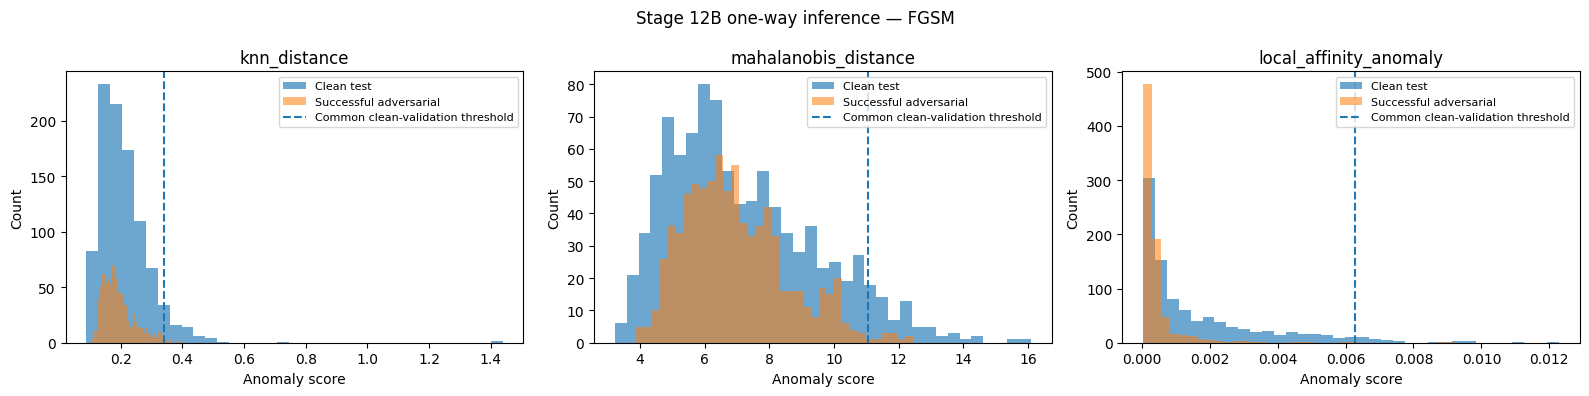

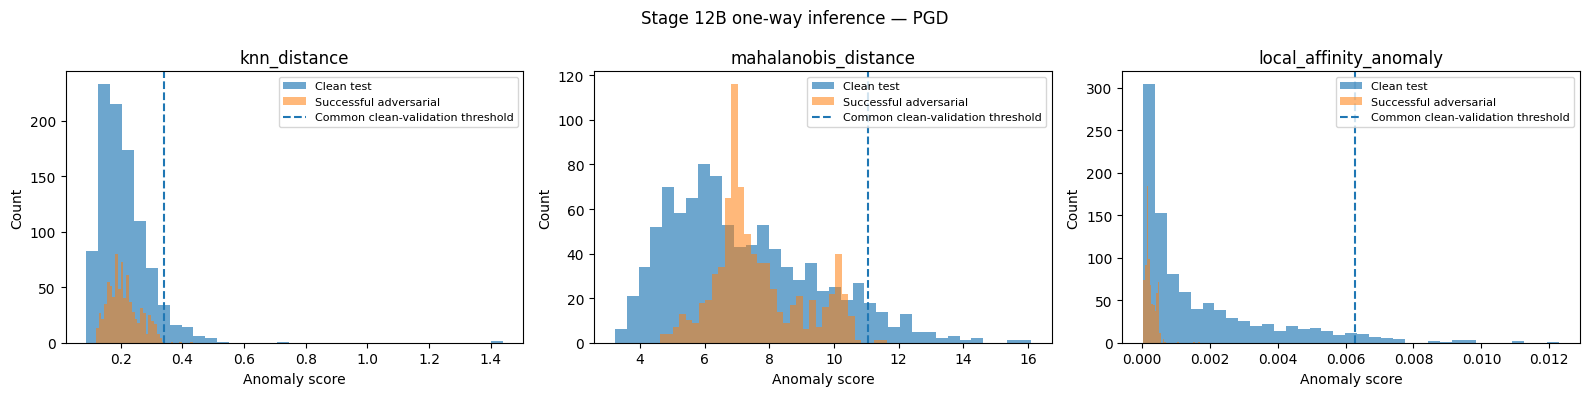

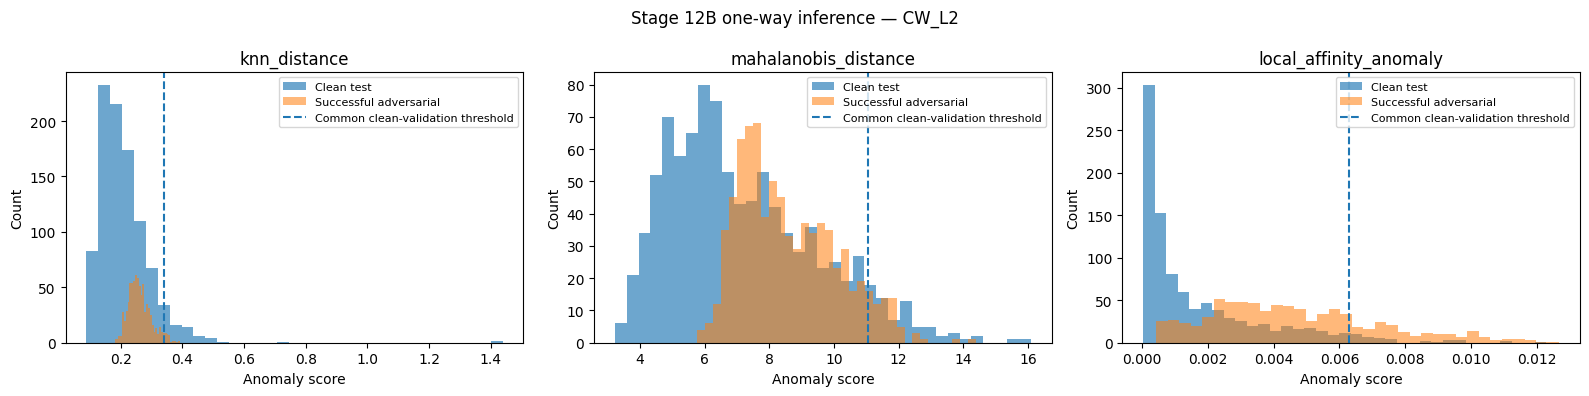

Saved: /content/drive/MyDrive/Alzheimer_DGI_Research/Stage12_Corrected_Outputs | Archive: /content/drive/MyDrive/Alzheimer_DGI_Research/Stage12B_Outputs.zip


,attack,method,common_threshold,clean_test_n,successful_adversarial_test_n,TN,FP,FN,TP,precision,recall,f1,accuracy,false_positive_rate,roc_auc,average_precision
0,FGSM,knn_distance,0.340176,960,793,904,56,783,10,0.151515,0.012610,0.023283,0.521392,0.058333,0.446153,0.396291
1,FGSM,mahalanobis_distance,11.052126,960,793,895,65,782,11,0.144737,0.013871,0.025316,0.516828,0.067708,0.501890,0.418392
2,FGSM,local_affinity_anomaly,0.006285,960,793,920,40,790,3,0.069767,0.003783,0.007177,0.526526,0.041667,0.256088,0.318289
3,PGD,knn_distance,0.340176,960,793,904,56,789,4,0.066667,0.005044,0.009379,0.517969,0.058333,0.540572,0.444428
4,PGD,mahalanobis_distance,11.052126,960,793,895,65,791,2,0.029851,0.002522,0.004651,0.511694,0.067708,0.604774,0.471484
5,PGD,local_affinity_anomaly,0.006285,960,793,920,40,793,0,0.000000,0.000000,0.000000,0.524815,0.041667,0.194381,0.305251
6,CW_L2,knn_distance,0.340176,960,793,904,56,754,39,0.410526,0.049180,0.087838,0.537935,0.058333,0.769801,0.603831
7,CW_L2,mahalanobis_distance,11.052126,960,793,895,65,738,55,0.458333,0.069357,0.120482,0.541928,0.067708,0.715738,0.565409
8,CW_L2,local_affinity_anomaly,0.006285,960,793,920,40,610,183,0.820628,0.230769,0.360236,0.629207,0.041667,0.842238,0.771041


In [15]:
# Hard validation checks before accepting results.
assert len(metrics_df)==9
assert set(metrics_df['attack'])==set(ATTACKS)
assert set(metrics_df['method'])==set(METHODS)
assert (metrics_df['clean_test_n']==960).all()
assert (metrics_df['successful_adversarial_test_n']==793).all()
assert np.isfinite(metrics_df[['precision','recall','f1','roc_auc','false_positive_rate']].to_numpy()).all()
assert (audit_df['clean_embedding_max_abs_difference']<1e-5).all()
assert (thresholds_df['calibration_n']==len(idx_val)).all()
assert thresholds_df['observed_validation_fpr'].between(0,0.06).all()
for method in METHODS:
    assert metrics_df.loc[metrics_df.method==method,'common_threshold'].nunique()==1

for attack in ATTACKS:
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    for ax,method in zip(axes,METHODS):
        d=scores_df[(scores_df.attack==attack)&(scores_df.method==method)]
        ax.hist(d.loc[d.sample_type=='clean','anomaly_score'],bins=35,alpha=.65,label='Clean test')
        ax.hist(d.loc[d.sample_type=='successful_adversarial','anomaly_score'],bins=35,alpha=.55,label='Successful adversarial')
        ax.axvline(common_thresholds[method],linestyle='--',label='Common clean-validation threshold')
        ax.set_title(method); ax.set_xlabel('Anomaly score'); ax.set_ylabel('Count'); ax.legend(fontsize=8)
    fig.suptitle(f'Stage 12B one-way inference — {attack}')
    fig.tight_layout()
    fig.savefig(OUT/f'stage12B_{attack}_score_distributions.png',dpi=180,bbox_inches='tight')
    plt.show()

metrics_df.to_csv(OUT/'stage12B_detection_metrics.csv',index=False)
thresholds_df.to_csv(OUT/'stage12B_common_thresholds.csv',index=False)
scores_df.to_csv(OUT/'stage12B_test_sample_scores.csv',index=False)
audit_df.to_csv(OUT/'stage12B_clean_embedding_isolation_audit.csv',index=False)

config={
 'stage':'12B','purpose':'One-way adversarial inference with frozen clean embeddings',
 'seed':SEED,'device':str(DEVICE),'k':K_NEIGHBORS,
 'clean_embeddings':'Original Stage 6 embeddings recomputed on original Stage 5 graph and held fixed',
 'reference_set':'Clean training embeddings only',
 'threshold_calibration':'One common 95th-percentile threshold per score from clean validation embeddings; shared across attacks',
 'inference_graph':'Directed adversarial-row to clean-column edges only; no clean-row to adversarial-column edges',
 'isolation_invariant':'Clean embeddings after adding adversarial nodes match original clean embeddings within 1e-5',
 'test_evaluation':'960 clean test nodes versus 793 successful Stage 7 adversarial samples per attack',
 'attack_labels_used_for_fit_or_threshold_selection':False,
 'test_labels_used_for_fit_or_threshold_selection':False,
 'stage6_limitation':'Stage 6 DGI was trained transductively on all 6400 clean nodes; Stage 12B does not remove this limitation.',
 'stage4_stage5_feature_max_abs_difference':max_feature_diff,
 'stage6_embedding_reconstruction_max_abs_difference':max_dgi_diff,
 'successful_test_attack_counts':{a:int(attack_data[('test',a)]['attack_success'].sum()) for a in ATTACKS}
}
with open(OUT/'stage12B_config.json','w') as f: json.dump(config,f,indent=2)
zip_path=ROOT/'Stage12B_Outputs.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as zf:
    for p in OUT.rglob('*'):
        if p.is_file(): zf.write(p,arcname=p.name)
print('Saved:',OUT,'| Archive:',zip_path)
display(metrics_df)


## 10. Interpretation and reporting cautions

1. **Do not expect the earlier Stage 12 metrics to repeat.** Those metrics came from random fallback vectors and are invalid.
2. The detection-positive class consists only of Stage 7 successful adversarial examples. Failed attack attempts are excluded from the positive class.
3. The clean test negative class contains all 960 clean test images. Therefore, each test evaluation has 960 negatives and 793 positives for the current Stage 7 test files.
4. The 95th-percentile threshold is selected from clean validation scores only. Its empirical validation FPR may be slightly below 5% because of quantile/tie handling.
5. Stage 5/6 used a transductive graph containing all 6,400 clean nodes. State this clearly in the manuscript. A separate inductive/train-only graph experiment would be needed to support claims about unseen-node generalisation.
6. Do not copy metrics into the manuscript until the output CSVs and all assertions have been reviewed.